#  Zomato Restaurant Data Analysis Using Python

Project Objective:

The objective of this project is to analyze Zomato restaurant data to understand restaurant distribution, customer ratings, online ordering availability, restaurant types, and average dining costs.

In [46]:
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv("zomato_compressed.csv.gz")

In [47]:
df.head(5)

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


In [48]:
df.shape  #Shows the number of rows and columns

(51717, 17)

In [49]:
df.info()  #Shows the Column namesColumn names Data types,Non-null values,Missing data information



<class 'pandas.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   url                          51717 non-null  str  
 1   address                      51717 non-null  str  
 2   name                         51717 non-null  str  
 3   online_order                 51717 non-null  str  
 4   book_table                   51717 non-null  str  
 5   rate                         43942 non-null  str  
 6   votes                        51717 non-null  int64
 7   phone                        50509 non-null  str  
 8   location                     51696 non-null  str  
 9   rest_type                    51490 non-null  str  
 10  dish_liked                   23639 non-null  str  
 11  cuisines                     51672 non-null  str  
 12  approx_cost(for two people)  51371 non-null  str  
 13  reviews_list                 51717 non-null  str  
 14  m

In [50]:
df.columns  #This displays all the column names.

Index(['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes',
       'phone', 'location', 'rest_type', 'dish_liked', 'cuisines',
       'approx_cost(for two people)', 'reviews_list', 'menu_item',
       'listed_in(type)', 'listed_in(city)'],
      dtype='str')

In [51]:
df.describe()
#Provides statistical information about numerical columns.

,votes
count,51717.000000
mean,283.697527
std,803.838853
min,0.000000
25%,7.000000
50%,41.000000
75%,198.000000
max,16832.000000


# data cleaning

In [52]:
df.isnull().sum()  #This tells us how many missing values are present in each column

url                                0
address                            0
name                               0
online_order                       0
book_table                         0
rate                            7775
votes                              0
phone                           1208
location                          21
rest_type                        227
dish_liked                     28078
cuisines                          45
approx_cost(for two people)      346
reviews_list                       0
menu_item                          0
listed_in(type)                    0
listed_in(city)                    0
dtype: int64

In [53]:
df.duplicated().sum()#This checks how many duplicate records exist.

np.int64(0)

In [54]:
df.drop_duplicates(inplace=True) # It removes duplicate  rows

In [55]:
df.drop(['url', 'address', 'phone', 'reviews_list', 'menu_item'],
        axis=1, inplace=True)
# it removes unnnecessary columns

In [56]:
df['rate'].unique()

<ArrowStringArray>
[ '4.1/5',  '3.8/5',  '3.7/5',  '3.6/5',  '4.6/5',  '4.0/5',  '4.2/5',
  '3.9/5',  '3.1/5',  '3.0/5',  '3.2/5',  '3.3/5',  '2.8/5',  '4.4/5',
  '4.3/5',    'NEW',  '2.9/5',  '3.5/5',      nan,  '2.6/5', '3.8 /5',
  '3.4/5',  '4.5/5',  '2.5/5',  '2.7/5',  '4.7/5',  '2.4/5',  '2.2/5',
  '2.3/5', '3.4 /5',      '-', '3.6 /5',  '4.8/5', '3.9 /5', '4.2 /5',
 '4.0 /5', '4.1 /5', '3.7 /5', '3.1 /5', '2.9 /5', '3.3 /5', '2.8 /5',
 '3.5 /5', '2.7 /5', '2.5 /5', '3.2 /5', '2.6 /5', '4.5 /5', '4.3 /5',
 '4.4 /5',  '4.9/5',  '2.1/5',  '2.0/5',  '1.8/5', '4.6 /5', '4.9 /5',
 '3.0 /5', '4.8 /5', '2.3 /5', '4.7 /5', '2.4 /5', '2.1 /5', '2.2 /5',
 '2.0 /5', '1.8 /5']
Length: 65, dtype: str

In [57]:
df['rate'] = df['rate'].str.replace('/5', '', regex=False)

In [58]:
df['rate'] = pd.to_numeric(df['rate'], errors='coerce')

In [59]:
df['rate'].head()

0    4.1
1    4.1
2    3.8
3    3.7
4    3.8
Name: rate, dtype: float64

In [60]:
df['approx_cost(for two people)'].unique()
#The cost column may be stored as text instead of numbers.


<ArrowStringArray>
[  '800',   '300',   '600',   '700',   '550',   '500',   '450',   '650',
   '400',   '900',   '200',   '750',   '150',   '850',   '100', '1,200',
   '350',   '250',   '950', '1,000', '1,500', '1,300',   '199',    '80',
 '1,100',   '160', '1,600',   '230',   '130',    '50',   '190', '1,700',
     nan, '1,400',   '180', '1,350', '2,200', '2,000', '1,800', '1,900',
   '330', '2,500', '2,100', '3,000', '2,800', '3,400',    '40', '1,250',
 '3,500', '4,000', '2,400', '2,600',   '120', '1,450',   '469',    '70',
 '3,200',    '60',   '560',   '240',   '360', '6,000', '1,050', '2,300',
 '4,100', '5,000', '3,700', '1,650', '2,700', '4,500',   '140']
Length: 71, dtype: str

In [61]:
df['approx_cost(for two people)'] = (
    df['approx_cost(for two people)']
    .str.replace(',', '', regex=False)
)
# removes  the commas

In [62]:
df['approx_cost(for two people)'] = pd.to_numeric(
    df['approx_cost(for two people)'],
    errors='coerce'
)
# converts to numeric

In [63]:
df.isnull().sum()

name                               0
online_order                       0
book_table                         0
rate                           10052
votes                              0
location                          21
rest_type                        227
dish_liked                     28078
cuisines                          45
approx_cost(for two people)      346
listed_in(type)                    0
listed_in(city)                    0
dtype: int64

In [64]:
df.dropna(subset=['rate', 'approx_cost(for two people)'], inplace=True)
# lets remove rows where  rating or cost is missing

In [65]:
df.isnull().sum()

name                               0
online_order                       0
book_table                         0
rate                               0
votes                              0
location                           0
rest_type                        147
dish_liked                     18091
cuisines                           8
approx_cost(for two people)        0
listed_in(type)                    0
listed_in(city)                    0
dtype: int64

In [66]:
# Check the cleaned dataset

print(df[['rate', 'location', 'online_order',
          'rest_type', 'approx_cost(for two people)']].head())

print(df.shape)

   rate      location online_order            rest_type  \
0   4.1  Banashankari          Yes        Casual Dining   
1   4.1  Banashankari          Yes        Casual Dining   
2   3.8  Banashankari          Yes  Cafe, Casual Dining   
3   3.7  Banashankari           No          Quick Bites   
4   3.8  Basavanagudi           No        Casual Dining   

   approx_cost(for two people)  
0                        800.0  
1                        800.0  
2                        800.0  
3                        300.0  
4                        600.0  
(41418, 12)


In [67]:
df.shape  # shows number of rows changed after cleaning.

(41418, 12)

In [68]:
location_counts = df['location'].value_counts().head(10)

print(location_counts)
# top 10 returant locations

location
BTM                      3906
Koramangala 5th Block    2297
HSR                      2004
Indiranagar              1803
JP Nagar                 1717
Jayanagar                1636
Whitefield               1577
Marathahalli             1428
Bannerghatta Road        1230
Koramangala 6th Block    1069
Name: count, dtype: int64


 top 10 returant locations

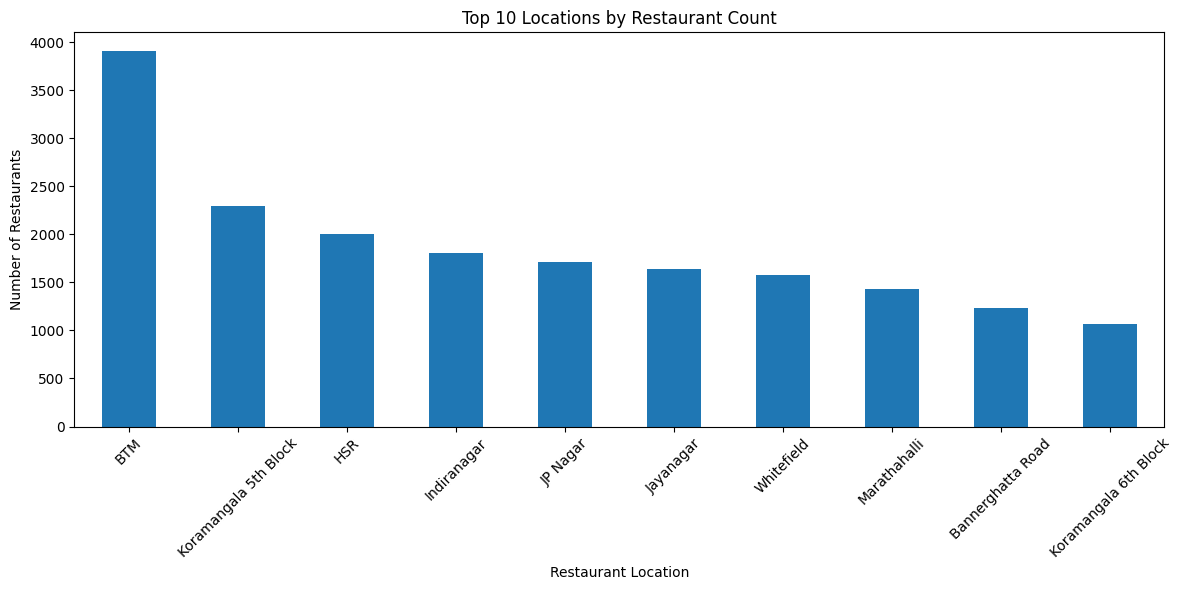

In [69]:
# Top 10 restaurant locations

location_counts = df['location'].value_counts().head(10)

plt.figure(figsize=(12,6))

location_counts.plot(kind='bar')

plt.title('Top 10 Locations by Restaurant Count')
plt.xlabel('Restaurant Location')
plt.ylabel('Number of Restaurants')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


#BTM has the highest concentration of restaurants

In [70]:
online_counts = df['online_order'].value_counts()

print(online_counts)
#Online Order Availability

online_order
Yes    27206
No     14212
Name: count, dtype: int64


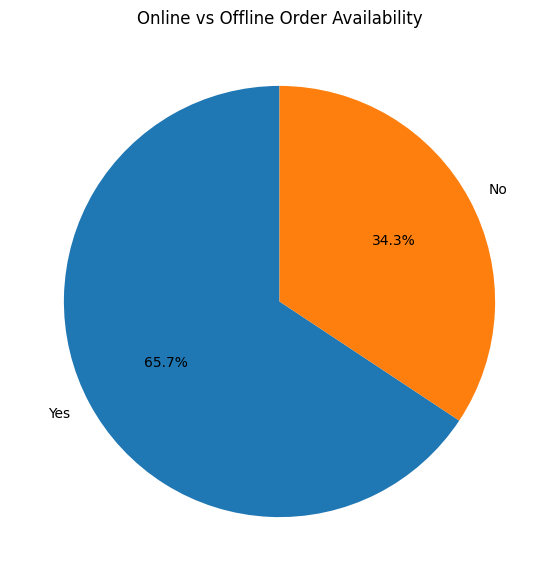

In [71]:
# Count online and offline orders

online_counts = df['online_order'].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    online_counts,
    labels=online_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Online vs Offline Order Availability')

plt.show()

#shows What percentage of restaurants accept online orders.

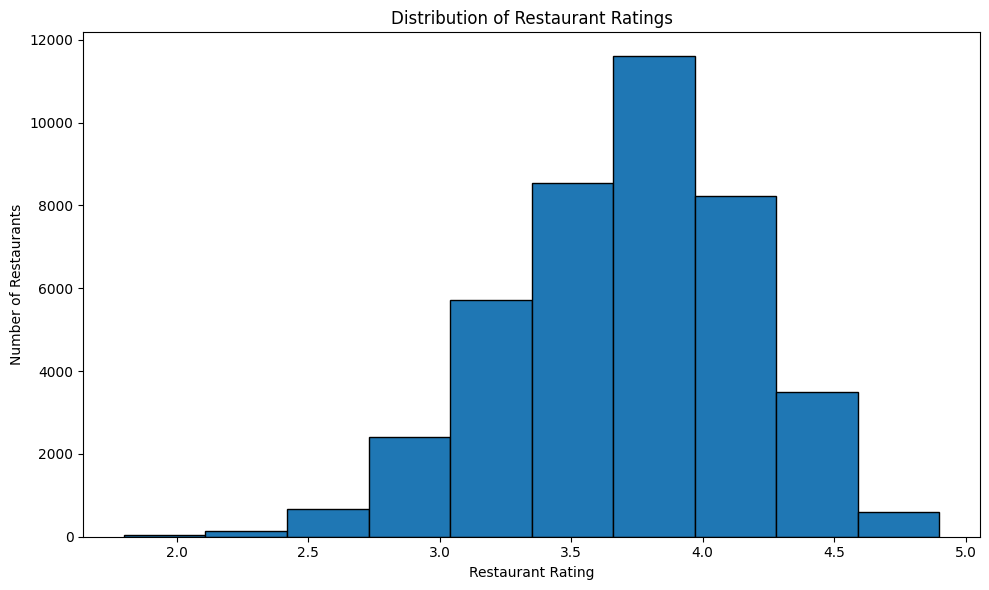

In [72]:
plt.figure(figsize=(10,6))

plt.hist(df['rate'].dropna(), bins=10, edgecolor='black')

plt.title('Distribution of Restaurant Ratings')
plt.xlabel('Restaurant Rating')
plt.ylabel('Number of Restaurants')

plt.tight_layout()
plt.show()
# shows  the Distribution of  Resturant Ratings

This helps us understand whether most restaurants have low, average, or high ratings.

#top 10 highly rated Restaurants

In [73]:
top_restaurants = df.sort_values(
    by='rate', ascending=False
).head(10)

print(top_restaurants[['name', 'location', 'rate']])

                                 name               location  rate
31069  Asia Kitchen By Mainland China  Koramangala 5th Block   4.9
12380          Belgian Waffle Factory           Brigade Road   4.9
14740          Belgian Waffle Factory           Brigade Road   4.9
37843          Belgian Waffle Factory           Brigade Road   4.9
47409          Belgian Waffle Factory           Brigade Road   4.9
9099   Asia Kitchen By Mainland China  Koramangala 5th Block   4.9
32110  Asia Kitchen By Mainland China  Koramangala 5th Block   4.9
47987          Belgian Waffle Factory           Brigade Road   4.9
19393       AB's - Absolute Barbecues                    BTM   4.9
39559                    Punjab Grill           Malleshwaram   4.9


#Average Rating by Location

In [74]:
avg_rating = df.groupby('location')['rate'].mean()

top_locations = avg_rating.sort_values(ascending=False).head(10)

print(top_locations)

location
Lavelle Road             4.141788
Koramangala 3rd Block    4.020419
St. Marks Road           4.017201
Koramangala 5th Block    4.006661
Church Street            3.992125
Sankey Road              3.965385
Koramangala 4th Block    3.918668
Cunningham Road          3.901053
Residency Road           3.864570
Koramangala 7th Block    3.852986
Name: rate, dtype: float64


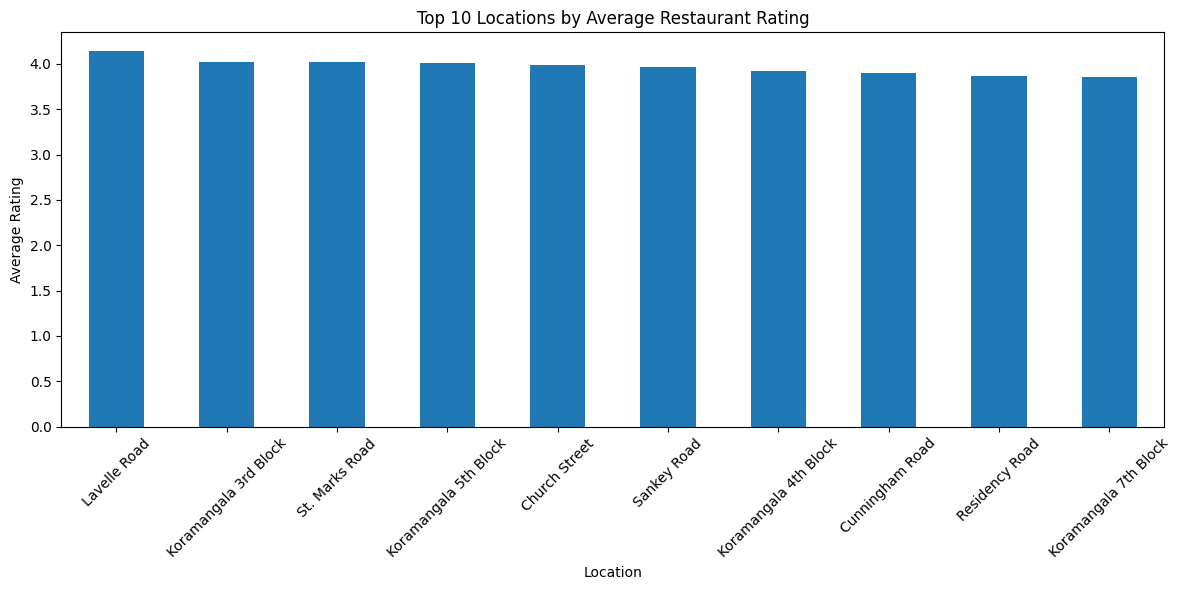

In [75]:
# Calculate average rating by location

avg_rating = df.groupby('location')['rate'].mean()

# Select top 10 locations

top_locations = avg_rating.sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(12,6))

top_locations.plot(kind='bar')

plt.title('Top 10 Locations by Average Restaurant Rating')
plt.xlabel('Location')
plt.ylabel('Average Rating')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#it shows Which locations have the highest average restaurant ratings.

In [76]:
online_rating = df.groupby('online_order')['rate'].mean()

print(online_rating)

online_order
No     3.658071
Yes    3.722440
Name: rate, dtype: float64


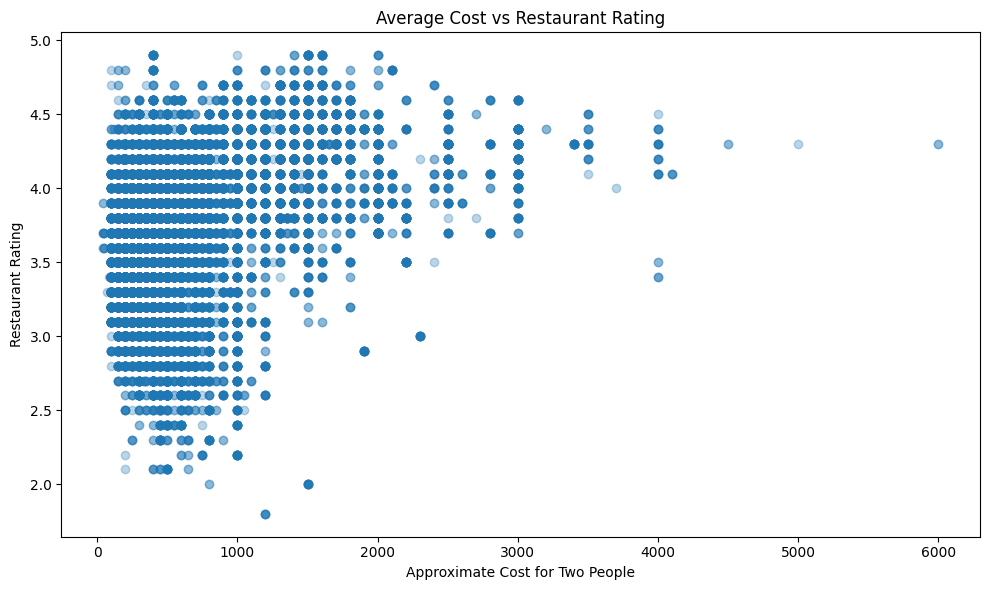

In [77]:
plt.figure(figsize=(10,6))

plt.scatter(
    df['approx_cost(for two people)'],
    df['rate'],
    alpha=0.3
)

plt.title('Average Cost vs Restaurant Rating')
plt.xlabel('Approximate Cost for Two People')
plt.ylabel('Restaurant Rating')

plt.tight_layout()
plt.show()

If points move upward as cost increases, there may be a positive relationship.
If points are scattered randomly, there may be a weak relationship.
Remember, correlation does not necessarily mean causation.

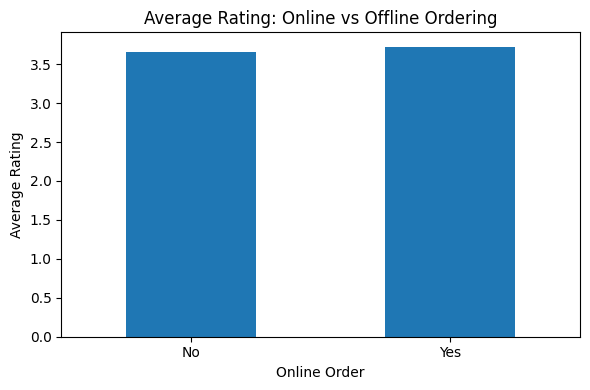

In [78]:
online_rating.plot(kind='bar', figsize=(6,4))

plt.title('Average Rating: Online vs Offline Ordering')
plt.xlabel('Online Order')
plt.ylabel('Average Rating')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#it shows Do restaurants accepting online orders have a higher average rating than restaurants that don't

In [79]:
rest_counts = df['rest_type'].value_counts().head(10)

print(rest_counts)
# common Restaurant types

rest_type
Quick Bites           13885
Casual Dining          9616
Cafe                   3369
Dessert Parlor         1850
Delivery               1671
Takeaway, Delivery     1279
Casual Dining, Bar     1092
Bakery                  704
Beverage Shop           642
Bar                     640
Name: count, dtype: int64


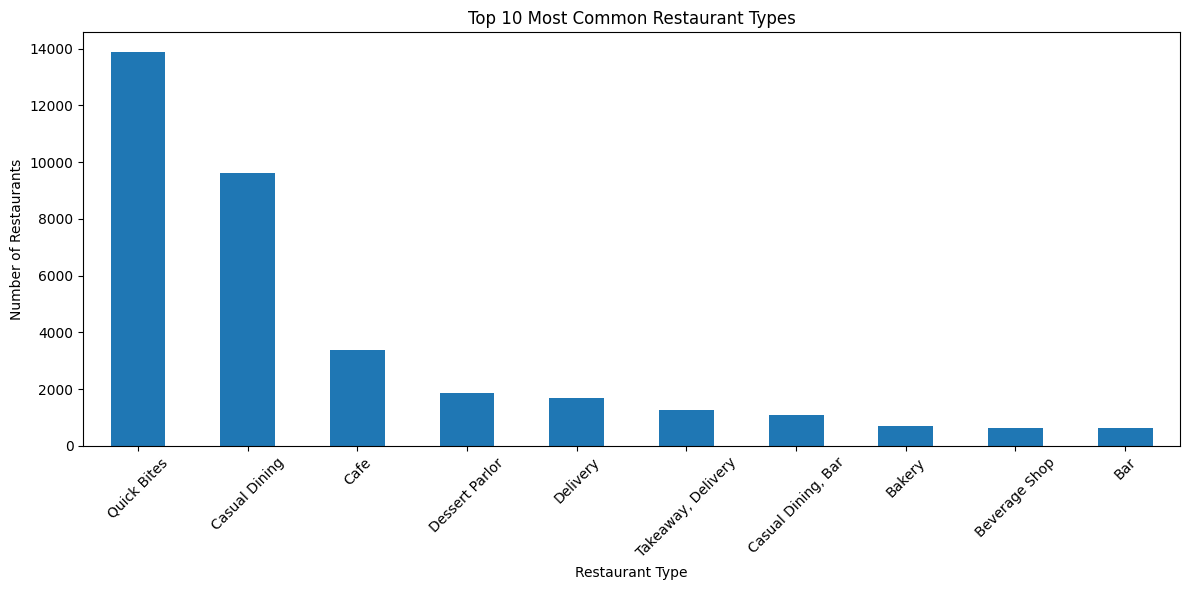

In [80]:
# Count restaurant types

rest_counts = df['rest_type'].value_counts().head(10)

plt.figure(figsize=(12,6))

rest_counts.plot(kind='bar')

plt.title('Top 10 Most Common Restaurant Types')
plt.xlabel('Restaurant Type')
plt.ylabel('Number of Restaurants')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#shows What types of restaurants are most common in the dataset

In [81]:
average_cost = df['approx_cost(for two people)'].mean()

print("Average cost for two people:", average_cost)
# cost Analysis

Average cost for two people: 603.2680477087257


In [82]:
#top  10 most Expensive  Restaurants

In [83]:
expensive = df.sort_values(
    by='approx_cost(for two people)',
    ascending=False
).head(10)

print(expensive[['name', 'location', 'approx_cost(for two people)']])

                                         name          location  \
19139  Le Cirque Signature - The Leela Palace  Old Airport Road   
45618  Le Cirque Signature - The Leela Palace  Old Airport Road   
40266              Royal Afghan - ITC Windsor       Sankey Road   
41591                  Malties - Radisson Blu      Marathahalli   
42141                  Malties - Radisson Blu      Marathahalli   
39416              La Brasserie - Le Meridien       Sankey Road   
40262              La Brasserie - Le Meridien       Sankey Road   
39125              La Brasserie - Le Meridien       Sankey Road   
37715              La Brasserie - Le Meridien       Sankey Road   
40278    Dum Pukht Jolly Nabobs - ITC Windsor       Sankey Road   

       approx_cost(for two people)  
19139                       6000.0  
45618                       6000.0  
40266                       5000.0  
41591                       4500.0  
42141                       4500.0  
39416                       4100.0  
402

# correlation Analysis

In [84]:


correlation_data = df[
    ['rate', 'votes', 'approx_cost(for two people)']
]

correlation_data.head()

,rate,votes,approx_cost(for two people)
0,4.1,775,800.0
1,4.1,787,800.0
2,3.8,918,800.0
3,3.7,88,300.0
4,3.8,166,600.0


In [85]:


correlation_matrix = correlation_data.corr()

correlation_matrix

,rate,votes,approx_cost(for two people)
rate,1.000000,0.434764,0.385183
votes,0.434764,1.000000,0.366700
approx_cost(for two people),0.385183,0.366700,1.000000


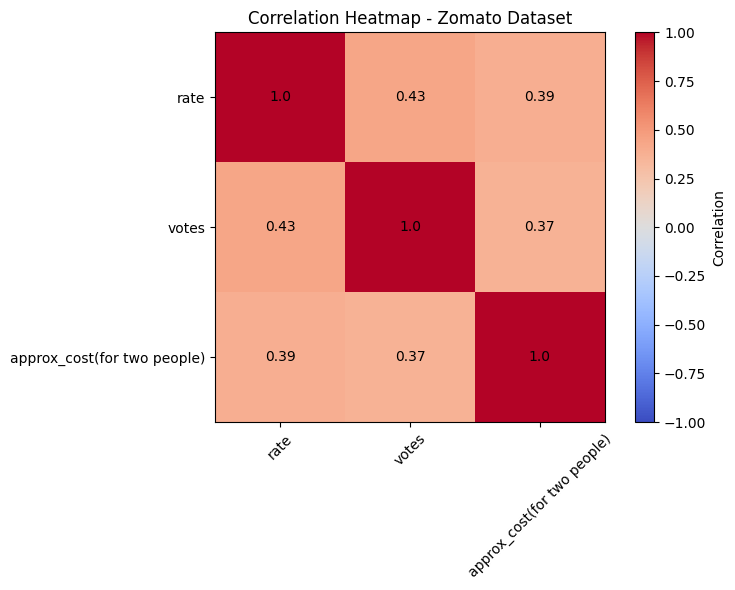

In [86]:
import matplotlib.pyplot as plt



plt.figure(figsize=(8,6))

plt.imshow(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1)

plt.colorbar(label='Correlation')

plt.xticks(range(len(correlation_matrix.columns)),
           correlation_matrix.columns, rotation=45)

plt.yticks(range(len(correlation_matrix.columns)),
           correlation_matrix.columns)

#  for Display correlation values

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(j, i,
                 round(correlation_matrix.iloc[i, j], 2),
                 ha='center', va='center')

plt.title('Correlation Heatmap - Zomato Dataset')

plt.tight_layout()
plt.show()

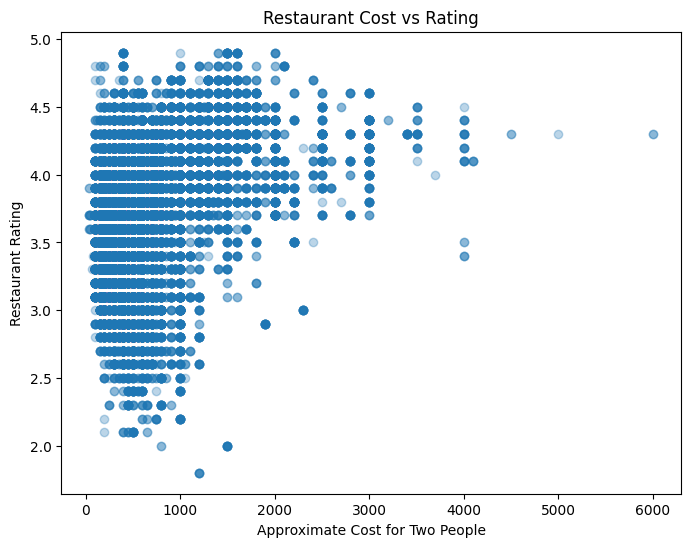

In [87]:
plt.figure(figsize=(8,6))

plt.scatter(
    df['approx_cost(for two people)'],
    df['rate'],
    alpha=0.3
)

plt.title('Restaurant Cost vs Rating')
plt.xlabel('Approximate Cost for Two People')
plt.ylabel('Restaurant Rating')

plt.show()
# it shows whether restaurant cost and ratings are related. 

#correlarion Analysis Findings

Examined the relationship between restaurant ratings and customer votes.
Analyzed the relationship between restaurant ratings and approximate restaurant costs.
Used a correlation matrix to identify positive and negative relationships.
Visualized numerical relationships using a correlation heatmap.

Project Findings
- Identified locations with the highest restaurant concentration.
- Analyzed the distribution of restaurant ratings.
- Compared online and offline ordering availability.
- Compared average ratings for online and offline restaurants.
- Identified the most common restaurant categories.
- Analyzed restaurant costs.
- Identified highly rated restaurants.